# A guide to single-cell plotting functions

*Python port of the R vignette [A guide to single-cell plotting functions](https://gregorlueg.github.io/bixverse/articles/single_cell_visualisation.html). Original author: Liesbeth François.*

## Intro

This vignette gives an overview of the different plotting functions that are
available when running a single cell analysis. The plots live in `bv.pl` and
need matplotlib (the `plots` extra); the `extract_*` functions next to them
return the data behind each plot as a polars frame.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed
from bixverse.params import NeighboursParams

## Preparing the data

We run the standard analysis using the same PBMC3k data set. For more details
on the data analysis itself, please refer to the
[PBMC vignette](pbmc_single_cell.ipynb). This vignette assumes familiarity
with how the `SingleCells` class, on-disk storage and cells-to-keep logic
work. To have something to group the QC by, every cell gets a random sample
label.

In [2]:
pbmc3k_path = bv.io.download_pbmc3k()

tempdir_pbmc = tempfile.TemporaryDirectory()

sc = bv.io.load_mtx(
    Path(tempdir_pbmc.name) / "pbmc3k",
    bv.io.get_cell_ranger_params(pbmc3k_path),
    verbose=True,
)

rng = np.random.default_rng(42)

sc.add_obs(pl.DataFrame({"sample": rng.choice(["sample1", "sample2"], sc.n_cells)}))

sc.rename_var_col("column1", "gene_symbol")

var = sc.var()

ensembl_to_symbol = dict(zip(var["gene_id"], var["gene_symbol"], strict=True))
symbol_to_ensembl = dict(zip(var["gene_symbol"], var["gene_id"], strict=True))

scrublet_res = bv.doublets.scrublet(sc)

sc.add_obs(bv.doublets.get_data(scrublet_res))

cells_without_doublets = sc.obs(cols=["cell_id", "doublet"]).filter(~pl.col("doublet"))[
    "cell_id"
]

sc.set_cells_to_keep(cells_without_doublets.to_list())

# define gene sets whose proportional expression signals low quality
gs_of_interest = {
    "MT": var.filter(pl.col("gene_symbol").str.contains("^MT-"))["gene_id"].to_list(),
    "Ribo": var.filter(pl.col("gene_symbol").str.contains("^RP[SL]"))[
        "gene_id"
    ].to_list(),
}

bv.qc.gene_set_proportions(sc, gs_of_interest, streaming=False, verbose=True)

# collect metrics for outlier detection
qc_df = sc.obs(cols=["cell_id", "sample", "lib_size", "nnz", "MT"], filtered=True)

metrics = {
    "log10_lib_size": np.log10(qc_df["lib_size"].to_numpy()),
    "log10_nnz": np.log10(qc_df["nnz"].to_numpy()),
    "MT": qc_df["MT"].to_numpy(),
}

directions = {
    "log10_lib_size": "twosided",
    "log10_nnz": "twosided",
    "MT": "above",
}

qc = bv.qc.run_cell_qc(
    metrics,
    sc.cells_to_keep,
    directions=directions,
    threshold=3.0,
    groups=qc_df["sample"],
)

Text pass (real): 1 buckets, ~2700 cells/bucket
Text pass done: 26.93ms (cell-major order)
Genes passing QC: 11_139 / 32_738
Cells passing QC: 2_700 / 2_700
Writing pass: 1 buckets, no sort
  Wrote bucket 1/1 (100%)
Writing pass done: 28.28ms
  Counted 2_269_399 non-zeros over 11_139 genes in 1.50ms; converting in 1 phase(s).
  Phase 1/1: genes 0-11139, scatter 6.05ms, compress + write 36.49ms
  Conversion into gene-friendly format done: 44.66ms


Load in data: 2.07ms
Finished the gene set proportion calculations: 635.83µs


## Joint QC plot

`joint_plot()` compares the number of features and number of counts per cell,
similar to `sns.jointplot`.

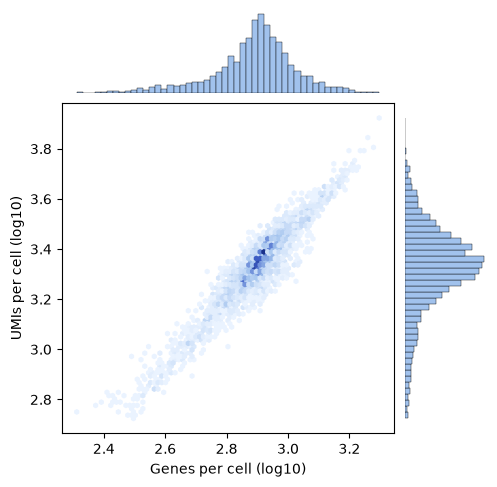

In [3]:
bv.pl.joint_plot(qc)
plt.show()

## Violin QC plots

`violin_plot()` shows the distribution of each QC metric as a violin, split by
donor (or any grouping variable stored in the `qc` object).

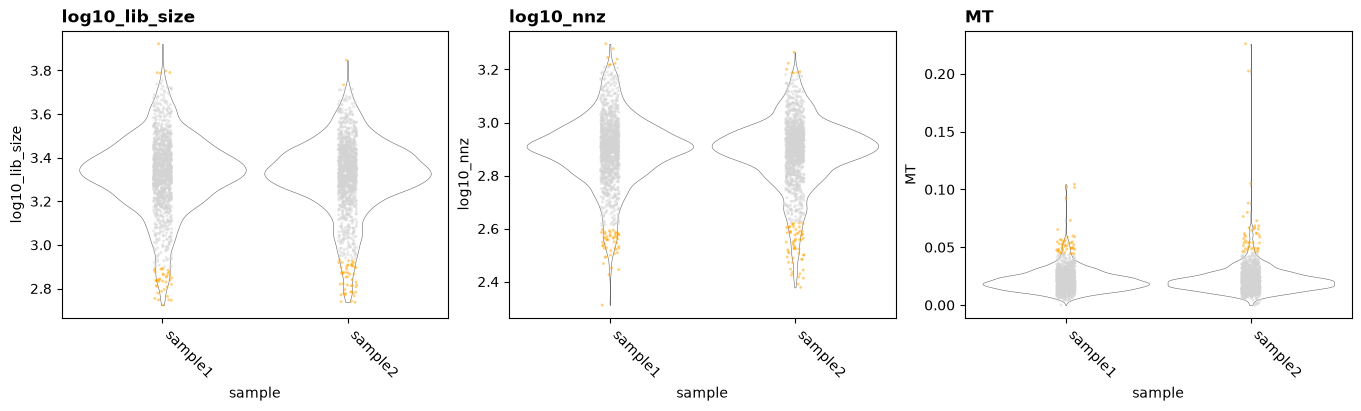

In [4]:
bv.pl.violin_plot(qc, group_name="sample")
plt.show()

Alternatively, we can also provide a frame and generate the violin plots with
different variables than those considered in the QC.

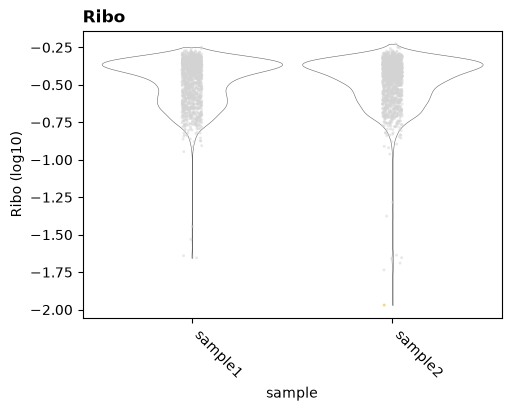

In [5]:
obs = sc.obs(filtered=True)

bv.pl.violin_plot(
    obs,
    grouping_column="sample",
    variable="Ribo",
    show_outlier=True,
)
plt.show()

## Density QC plots

`density_plot()` overlays smoothed density distributions for each group,
which highlights bimodal distributions or outlier populations that violins
can obscure.

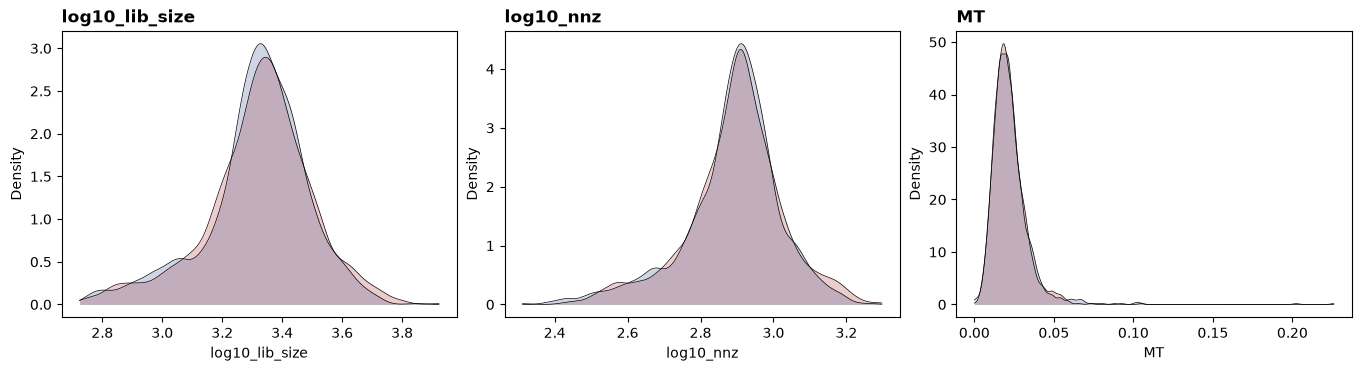

In [6]:
bv.pl.density_plot(qc)
plt.show()

## Dimensionality reduction plots

After PCA, neighbour-finding, clustering and UMAP, cells can be visualised on
any 2D embedding stored in the object. The scType annotation from the
[PBMC vignette](pbmc_single_cell.ipynb) gives us cell types to colour by.

In [7]:
bv.pp.find_hvg(sc, hvg_no=2000, verbose=True)

bv.pp.calculate_pca(sc, no_pcs=30, sparse_svd=True)

# the data is so tiny that exhaustive kNN search is faster than building
# an approximate nearest neighbour index
bv.graph.find_neighbours(
    sc, neighbours_params=NeighboursParams(knn_method="exhaustive")
)

bv.graph.find_clusters(sc, res=0.5, name="leiden_clusters")

bv.embed.umap(sc)

cell_markers = {
    "CD3D": "T cells",
    "CD3E": "T cells",
    "CD3G": "T cells",
    "IL7R": "CD4+ T",
    "CD4": "CD4+ T",
    "CD8A": "CD8+ T",
    "CD8B": "CD8+ T",
    "MS4A1": "B cells",
    "CD79A": "B cells",
    "CD19": "B cells",
    "CD14": "CD14+ Mono",
    "LYZ": "CD14+ Mono",
    "S100A8": "CD14+ Mono",
    "FCGR3A": "CD16+ Mono",
    "CDKN1C": "CD16+ Mono",
    "GNLY": "NK",
    "NKG7": "NK",
    "NCAM1": "NK",
    "FCER1A": "mDC",
    "CD1C": "mDC",
    "LILRA4": "pDC",
    "CLEC4C": "pDC",
    "PPBP": "Platelet",
    "PF4": "Platelet",
}

cell_markers_df = pl.DataFrame(
    {"gene_symbol": list(cell_markers), "cell_type": list(cell_markers.values())}
).join(var.select("gene_symbol", "gene_id"), on="gene_symbol")

# prepare the list of markers
marker_list = bv.annotate.prepare_cell_markers(sc, cell_markers_df)
# calculate the score for each cell
sctype_scores = bv.annotate.calc_sc_type_scores(sc, marker_list)
# annotate the clusters
leiden = sc.obs(cols=["leiden_clusters"], filtered=True)["leiden_clusters"]
cell_type_anno = bv.annotate.score_clusters(sctype_scores, leiden.to_numpy())

sc.add_obs(
    sc.obs(cols=["cell_idx", "leiden_clusters"], filtered=True)
    .join(
        cell_type_anno.select(
            pl.col("cluster_id").alias("leiden_clusters"),
            pl.col("cell_type").alias("sc_type"),
        ),
        on="leiden_clusters",
        how="left",
    )
    .select("cell_idx", "sc_type")
)

HVG (VST): 11_139 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 3.85ms
HVG (VST): Fitted Loess in 615.33µs
HVG (VST): Standardised variance in 908.21µs (1_173 gene(s) re-read for the clip)
HVG (VST): Total run time -> 5.42ms


**Colouring by cluster**

We can plot the UMAP embedding highlighting the Leiden clusters.

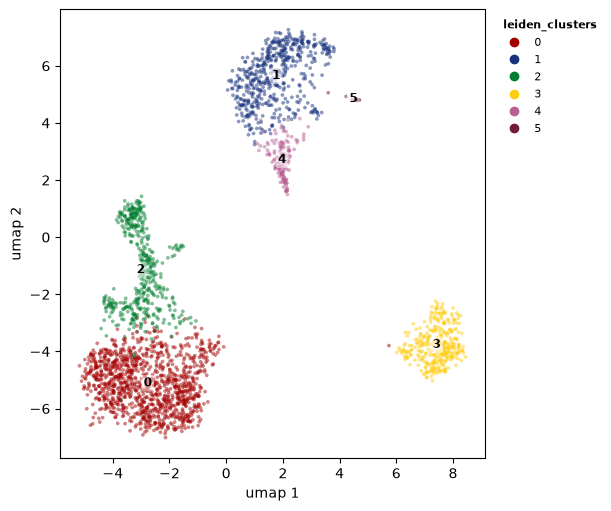

In [8]:
bv.pl.embedding_plot(
    sc,
    "umap",
    "leiden_clusters",
    label_by="leiden_clusters",
    discrete=True,
)
plt.show()

**Colouring by a discrete variable**

Pass any column from the cell metadata to `colour_by`. Use `label_by` to
overlay text labels at the cluster centroid. These do not need to be the same
variables.

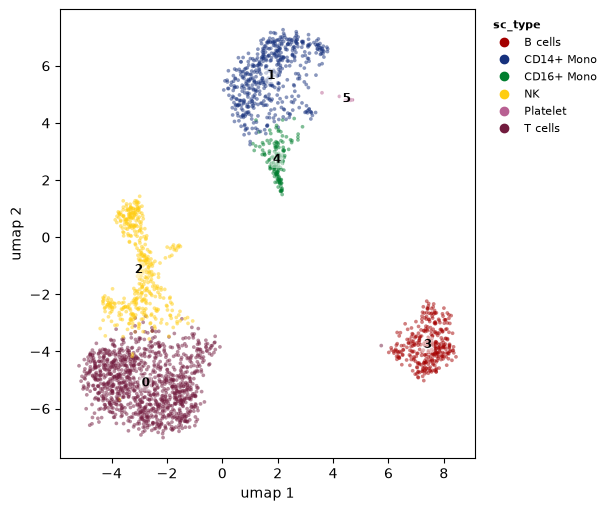

In [9]:
bv.pl.embedding_plot(
    sc,
    "umap",
    "sc_type",
    label_by="leiden_clusters",
    discrete=True,
)
plt.show()

**Colouring by a continuous variable**

Set `discrete=False` to use a continuous colour scale: useful for confidence
scores, pseudotime, or gene module scores.

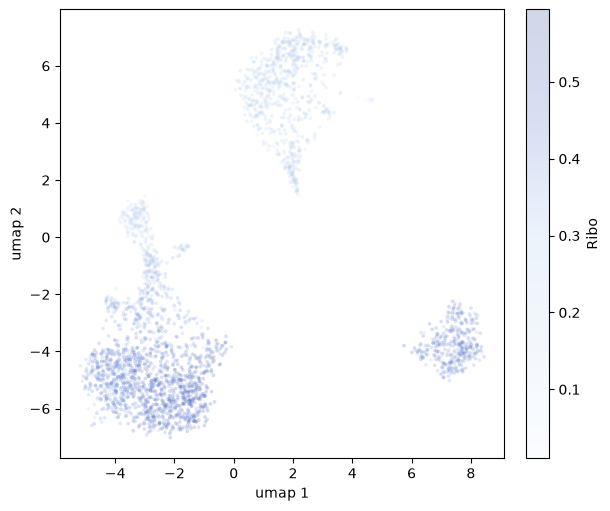

In [10]:
bv.pl.embedding_plot(
    sc,
    "umap",
    "Ribo",
    discrete=False,
    point_alpha=0.2,
)
plt.show()

**Key arguments:**

| Argument | Description |
|---|---|
| `embedding` | Name of the stored embedding (`"umap"`, `"tsne"`, `"pca"`, ...) |
| `colour_by` | Metadata column used to colour points |
| `label_by` | Metadata column used to label centroids |
| `discrete` | `True` for categorical palettes, `False` for continuous |
| `point_alpha` | Transparency (0 to 1); reduce for dense data sets |
| `ax` | matplotlib axes to draw on, for multi-panel figures |

**Extracting the plotting data**

Alternatively, you can also extract the plotting data directly to make
customised plots.

In [11]:
df = bv.pl.extract_embedding_data(
    sc,
    "umap",
    obs_cols=["sc_type", "leiden_clusters", "Ribo"],
)

df.head()

cell_id,dim_1,dim_2,sc_type,leiden_clusters,Ribo
str,f64,f64,str,i32,f64
"""AAACATACAACCAC-1""",-2.789345,-3.313207,"""T cells""",0,0.437138
"""AAACATTGATCAGC-1""",-5.099643,-5.040126,"""T cells""",0,0.317112
"""AAACCGTGCTTCCG-1""",1.875906,4.050531,"""CD14+ Mono""",1,0.243161
"""AAACCGTGTATGCG-1""",-2.765095,-0.071998,"""NK""",2,0.149132
"""AAACGCACTGGTAC-1""",-4.192035,-4.056669,"""T cells""",0,0.36351


## Other 2D embeddings

UMAP is not the only game in town. All the 2D embeddings come from
[manifolds-rs](https://github.com/GregorLueg/manifolds-rs) and land in the
same object, so `embedding_plot()` works on every one of them.

### Density-preserving embeddings

UMAP and t-SNE throw away local density. A tight, homogeneous population and a
diffuse, heterogeneous one come out at roughly the same size, so reading
anything into the area a cluster takes up on the plot is a mistake. densMAP
and den-SNE fix this with an extra term in the loss that keeps the local
radius of each cell in the embedding correlated with its radius in PCA space.
Big blob now means lots of variation, small tight blob means not much.
`lambda_` on `bv.embed.densmap_defaults()` and `bv.embed.densne_defaults()`
sets how hard that term pulls; `lambda_=0` gives you plain UMAP and t-SNE
back.

The t-SNE flavours come with four optimisers via `approx`: `"barnes_hut"`
(classic Barnes-Hut), `"qd"` (the quick-and-dirty Barnes-Hut of qdtsne, tree
depth capped via `max_depth` on the optimiser parameters, coarser by design),
`"fft"` (FIt-SNE style interpolation) and `"fft_3k"` (its three-kernel
variant). Here we use `"fft_3k"`. The estimators are sklearn style, so
`set_params` swaps the optimiser on the defaults.

In [12]:
bv.embed.densmap(sc)
bv.embed.tsne(sc, params=bv.embed.tsne_defaults().set_params(approx="fft_3k"))
bv.embed.densne(sc, params=bv.embed.densne_defaults().set_params(approx="fft_3k"))

UMAP and t-SNE (left) next to their density-preserving versions (right),
coloured by cell type. Every plot takes an `ax`, so a grid is just
`plt.subplots`.

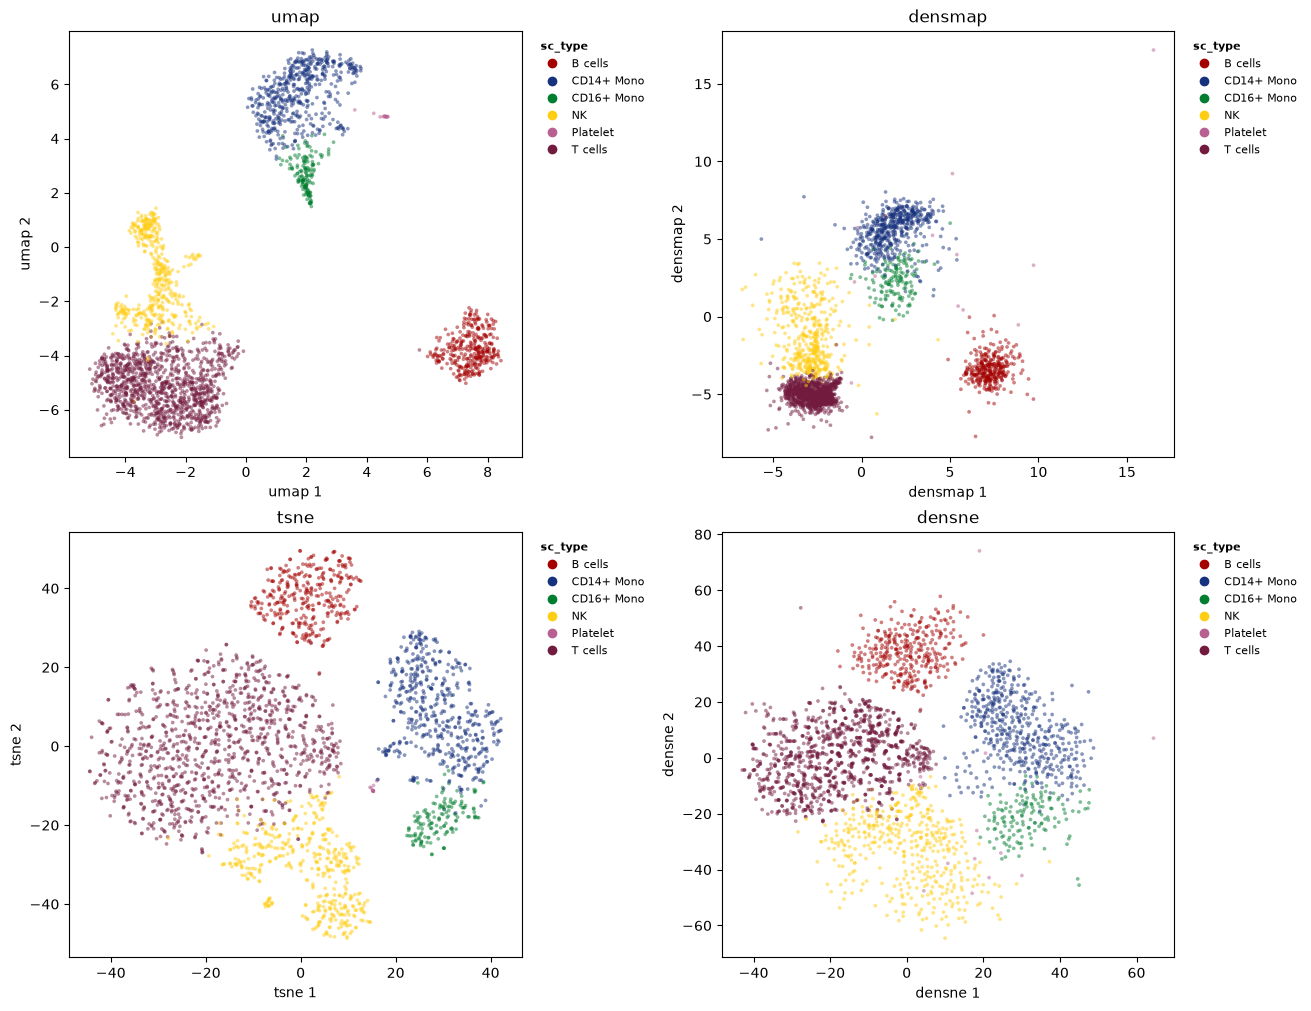

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), layout="constrained")

for ax, embd in zip(axes.flat, ["umap", "densmap", "tsne", "densne"], strict=True):
    bv.pl.embedding_plot(sc, embd, "sc_type", discrete=True, ax=ax)
    ax.set_title(embd)

plt.show()

### ForceAtlas2

ForceAtlas2 is a force-directed layout of the neighbour graph: edges pull,
every pair of cells pushes, gravity keeps the lot together. It is what
scanpy's `draw_graph()` does, and a common pick for data with continuous
transitions (think differentiation). `bv.embed.forceatlas2()` lays out the
kNN graph the same way scanpy does.

Not ported to Python yet: the layout of the neighbour graph the Leiden
clustering ran on (R's `graph = "connectivities"`), the `manifolds-rs` wheel
cannot lay out a given graph.

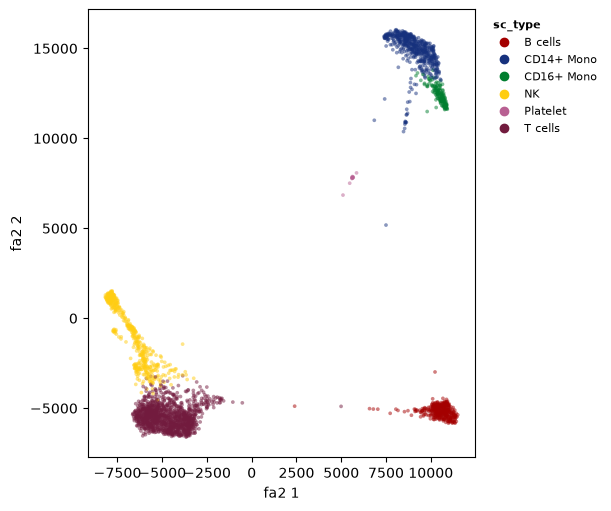

In [14]:
bv.embed.forceatlas2(sc)

bv.pl.embedding_plot(sc, "fa2", "sc_type", discrete=True)
plt.show()

## Per-gene expression plots

`feature_plot()` projects normalised expression of one or more genes onto the
embedding. Here MS4A1: the high-expressing cells sit in the B cell cluster,
as they should.

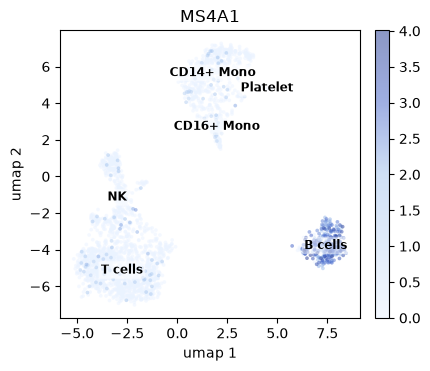

In [15]:
features = [symbol_to_ensembl[s] for s in cell_markers if s in symbol_to_ensembl]
feature_labels = {f: ensembl_to_symbol[f] for f in features}

ms4a1 = symbol_to_ensembl["MS4A1"]

bv.pl.feature_plot(
    sc,
    [ms4a1],
    "umap",
    feature_labels=feature_labels,
    label_by="sc_type",
)
plt.show()

**Tip:** pass a list of Ensembl IDs to `features` and a matching
`feature_labels` dict to produce one panel per gene.

We can also highlight the genes of interest for clearer visualisation.

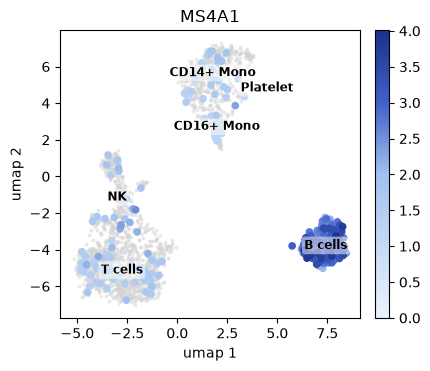

In [16]:
bv.pl.feature_plot(
    sc,
    [ms4a1],
    "umap",
    feature_labels=feature_labels,
    label_by="sc_type",
    highlight_features=True,
)
plt.show()

**Extracting the plotting data**

Alternatively, you can also extract the plotting data directly to make
customised plots.

In [17]:
df = bv.pl.extract_feature_plot_data(
    sc,
    [ms4a1],
    "umap",
    obs_cols=["sc_type", "leiden_clusters", "Ribo"],
)

df.head()

cell_id,dim_1,dim_2,sc_type,leiden_clusters,Ribo,gene,expression
str,f64,f64,str,i32,f64,enum,f64
"""AAACATACAACCAC-1""",-2.789345,-3.313207,"""T cells""",0,0.437138,"""ENSG00000156738""",0.0
"""AAACATTGATCAGC-1""",-5.099643,-5.040126,"""T cells""",0,0.317112,"""ENSG00000156738""",0.0
"""AAACCGTGCTTCCG-1""",1.875906,4.050531,"""CD14+ Mono""",1,0.243161,"""ENSG00000156738""",0.0
"""AAACCGTGTATGCG-1""",-2.765095,-0.071998,"""NK""",2,0.149132,"""ENSG00000156738""",0.0
"""AAACGCACTGGTAC-1""",-4.192035,-4.056669,"""T cells""",0,0.36351,"""ENSG00000156738""",0.0


## Dot plots

Dot plots encode two dimensions simultaneously:

- **Dot size**: fraction of cells in the group expressing the gene (at least
  one count)
- **Dot colour**: mean (scaled) expression among expressing cells

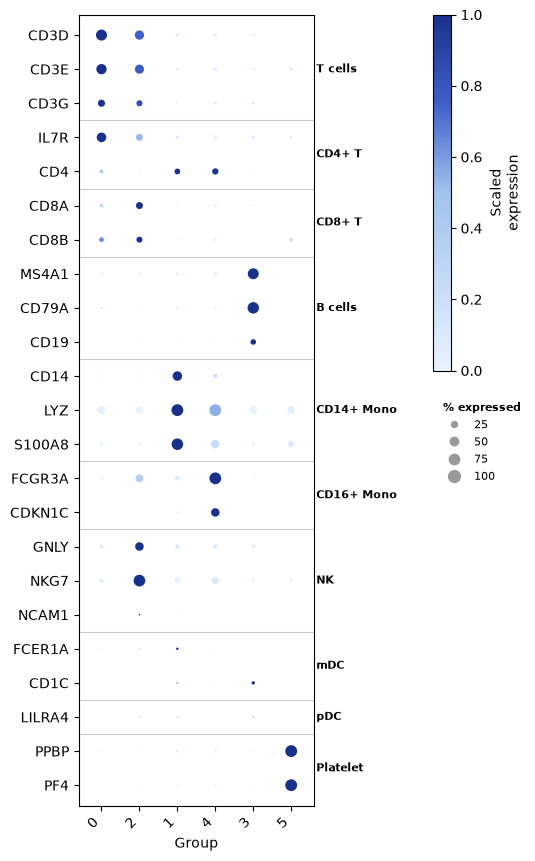

In [18]:
bv.pl.dot_plot(
    sc,
    features,
    "leiden_clusters",
    feature_labels=feature_labels,
    scale_exp=True,
    # keyed by the display label, here the symbol
    feature_grouping=cell_markers,
    cluster_groups=True,
)
plt.show()

**Key arguments:**

| Argument | Description |
|---|---|
| `features` | Ensembl IDs to plot |
| `feature_labels` | Display names shown on the axis |
| `grouping_variable` | Cell metadata column defining rows |
| `scale_exp` | Scale expression per gene (z-score) |
| `feature_grouping` | Dict mapping gene to group label for the x-axis brackets |
| `cluster_groups` | Hierarchically cluster rows by expression profile |

**Extracting the plotting data**

Alternatively, you can also extract the plotting data directly to make
customised plots.

In [19]:
df = bv.pl.extract_dot_plot_data(sc, features, "leiden_clusters")

df.head()

gene,group,mean_exp,pct_exp,scaled_exp
enum,enum,f64,f64,f64
"""ENSG00000167286""","""0""",2.122633,87.139106,1.0
"""ENSG00000167286""","""1""",0.140642,8.59375,0.066258
"""ENSG00000167286""","""2""",1.59509,60.99773,0.751467
"""ENSG00000167286""","""3""",0.070705,3.903904,0.03331
"""ENSG00000167286""","""4""",0.096548,6.756756,0.045485


## Heatmaps

Dot plots summarise each group. Want to see every single cell instead? The
marker heatmap puts genes on the rows and cells on the columns, with a gap
between clusters. Expression is z-scored per gene and clipped at 2.5 by
default, otherwise a few extreme cells eat the whole colour range.

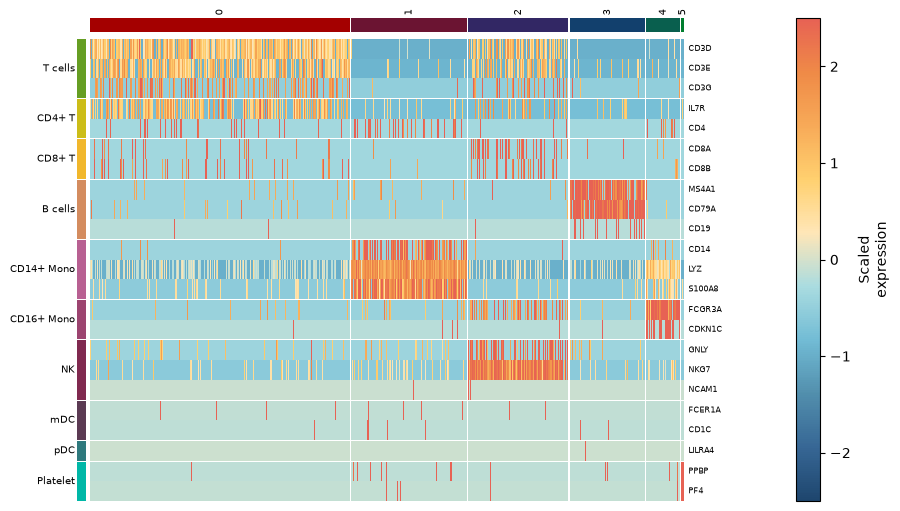

In [20]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")

bv.pl.heatmap_plot(
    sc,
    features,
    "leiden_clusters",
    feature_labels=feature_labels,
    feature_grouping=cell_markers,
    ax=ax,
)
plt.show()

Big clusters hog the width and the platelets end up as a sliver.
`max_cells_per_group` subsamples every group, which gives the small ones a
fair share of the plot.

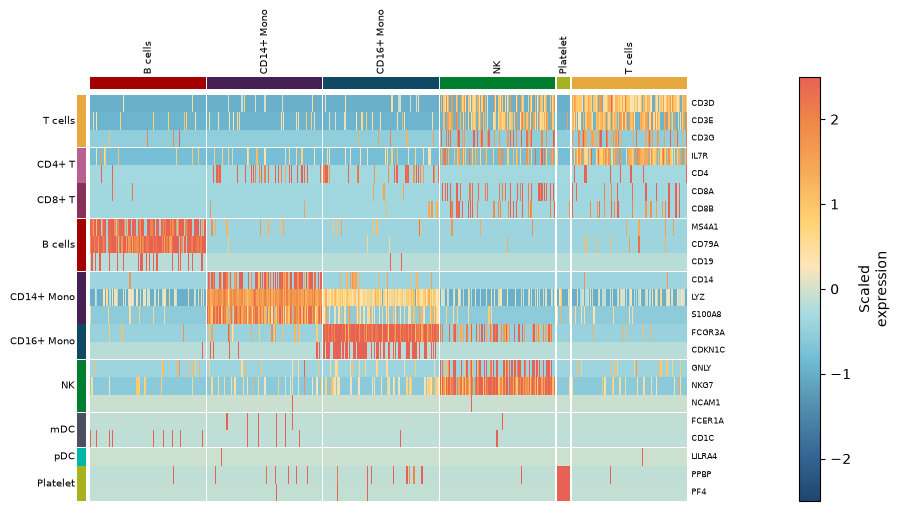

In [21]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")

bv.pl.heatmap_plot(
    sc,
    features,
    "sc_type",
    feature_labels=feature_labels,
    feature_grouping=cell_markers,
    max_cells_per_group=100,
    ax=ax,
)
plt.show()

The data behind it comes from `extract_gene_expression()`, in case you want to
build your own.

## Stacked violin plots

Stacked violins show the per-group expression distribution of several genes
in a compact vertical layout.

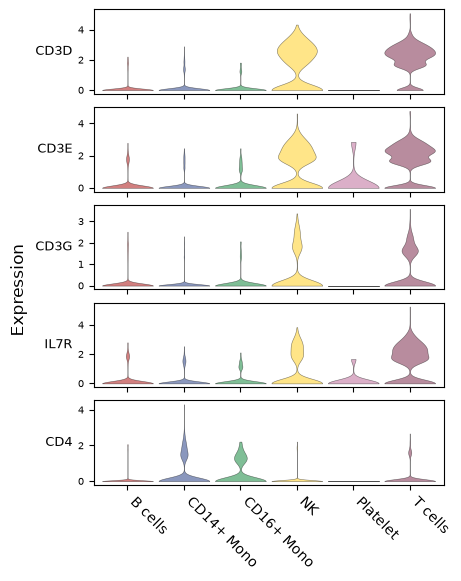

In [22]:
# take the first five markers
bv.pl.stacked_violin_plot(
    sc,
    features[:5],
    "sc_type",
    feature_labels=feature_labels,
)
plt.show()

**Extracting the plotting data**

In [23]:
df = bv.pl.extract_gene_violin_data(sc, features, "sc_type")

df.head()

cell_id,group,gene,expression
str,enum,enum,f64
"""AAACATACAACCAC-1""","""T cells""","""ENSG00000167286""",2.865234
"""AAACATTGATCAGC-1""","""T cells""","""ENSG00000167286""",3.490234
"""AAACCGTGCTTCCG-1""","""CD14+ Mono""","""ENSG00000167286""",0.0
"""AAACCGTGTATGCG-1""","""NK""","""ENSG00000167286""",0.0
"""AAACGCACTGGTAC-1""","""T cells""","""ENSG00000167286""",1.730469


## Clean up

In [24]:
tempdir_pbmc.cleanup()